## 小组作业2：高频抛硬币（泊松与指数分布模拟）
**【任务背景】**
模拟一台高频抛硬币机：总时间 $T = 1$ 秒，切分为 $10,00$ 个微小时间片（$\Delta t = 0.001$ 秒）。每个时间片内抛出正面的概率极小（$p = 0.002$）。

**【实验步骤】**
* **任务 A：数个数（模拟泊松分布）**
  * **算法**：写 `for` 循环跑 $1000$ 次，用 `random() < 0.002` 判定并统计这 1 秒内抛出的“正面总个数”。
  * **操作**：重复 $5,000$ 遍，画出“正面个数”的直方图。

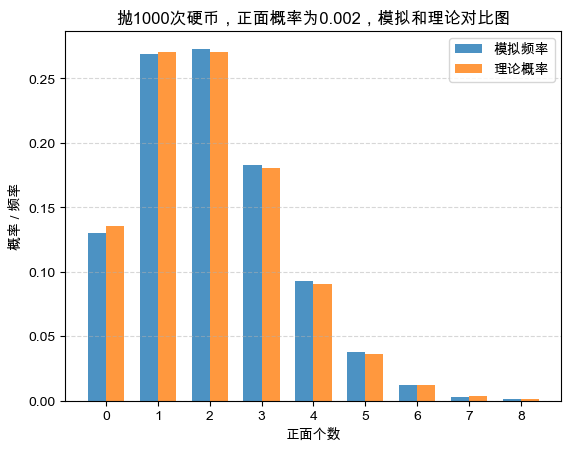

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import factorial

# 设置中文字体（防止画图中文乱码）
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

#---- 抛1000次硬币，统计正面个数，正面概率为0.002，这个动作重复5000次-----------
X = np.random.choice([1, 0], size=(5000, 1000), p=[0.002, 0.998])

#---- 统计模拟频率
sim_probs = np.bincount(X.sum(axis=1)) / 5000

#---- 计算泊松分布概率
lambda_val = 1000 * 0.002  # 期望值
N = len(sim_probs)
X_values = np.arange(N)
theo_probs = [np.exp(-lambda_val) * (lambda_val**k) / factorial(k) for k in range(N)]


#---- 绘制模拟和理论对比图，X_values为0到N-1的整数序列 ----
width = 0.35
plt.bar(
    X_values - width / 2, sim_probs, width, label="模拟频率", alpha=0.8
)
plt.bar(
    X_values + width / 2, theo_probs, width, label="理论概率", alpha=0.8
)
plt.xticks(X_values)
plt.xlabel("正面个数")
plt.ylabel("概率 / 频率")
plt.title("抛1000次硬币，正面概率为0.002，模拟和理论对比图")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


* **任务 B：等多久（模拟指数分布）**
  * **算法**：写 `while` 循环不断判定 `random() < 0.002`。若未抛出，时间累加 $t = t + 0.001$；一旦抛出立刻停止，记录“首次等待时间 $t$”。
  * **操作**：重复 $5,000$ 遍，画出“等待时间 $t$”的直方图。

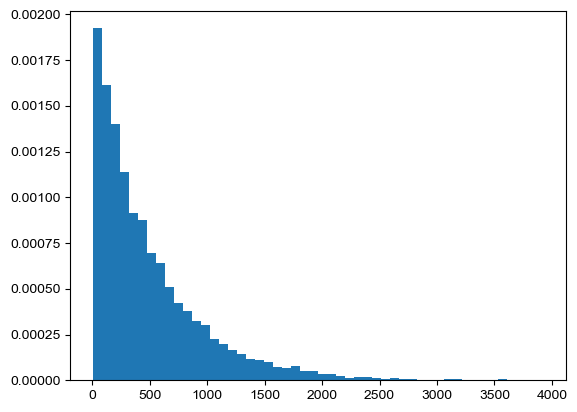

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import factorial

# 设置中文字体（防止画图中文乱码）
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

#---- 抛1000*5000次硬币，统计正面出现的等待时间-----------
X = np.random.choice([1, 0], size=(5000, 1000), p=[0.002, 0.998])
H_pos = np.nonzero(X.flatten())[0]

#---- 统计等待时间
wait_times = np.diff(H_pos) + 1

N = 50
plt.hist(wait_times, bins=N, density=True)

## --- 计算指数分布的理论概率
lambda_val = 1000 * 0.002
# 平均等待时间的倒数，即指数分布的参数
x_values = np.arange(0, N + 1)
theo_probs = lambda_val * np.exp(-lambda_val * x_values) 

#绘制理论曲线
#plt.plot(x_values, theo_probs, label="理论概率")
#plt.legend()







